In [1]:
import json

with open("reviews.json", encoding="utf-8") as f:
    data = json.load(f)

print(list(data.keys()))
print(data["archive_note"])
print(data["trusted_reference"][0])
print(data["samples"][0])
print(len(data["trusted_reference"]), len(data["samples"]))

['trusted_reference', 'samples', 'archive_note']
The altered records leave numbers. Sort their sample_index values numerically, join them with commas and no spaces, and take the SHA-256 of that UTF-8 text. That fingerprint is a 32-byte mask. Every archive_tag is hex: XOR its bytes with the mask and discard trailing zero bytes. The school's message is in one of the archive's seals, including those filed with the trusted reviews.
{'review_text': 'These screws fit my project guitar perfectly and considering it was an older Epiphone by Gibson S–900 that I opted to add a pick guard too, the screws fit everything perfectly. The look of the screws was even better than the cheap one you find on most import and low end made guitars the have the fat heads and strip really easy. I will purchase again for my next build.', 'summary': 'Fender Pickguard Screws', 'rating': 5, 'archive_tag': '9eede448e970c4272ab3b2cf367caaa8fb8e69a53d65db63903ca3b5eba07f64'}
{'sample_index': 0, 'review_text': 'I wanted

In [2]:
import pandas as pd

ref = pd.DataFrame(data["trusted_reference"])
samp = pd.DataFrame(data["samples"])

ref["text"] = ref["summary"] + " " + ref["review_text"]
samp["text"] = samp["summary"] + " " + samp["review_text"]

print(ref["rating"].value_counts())
print(ref.head())

rating
5    382
3    310
4    118
2    104
1     86
Name: count, dtype: int64
                                         review_text  \
0  These screws fit my project guitar perfectly a...   
1  This stand is probably one of the most popular...   
2  Works as described.  For the price I have no c...   
3  The peg winder is what it is, it winds pegs an...   
4  i knew it would be small but i wasn't thinking...   

                                            summary  rating  \
0                           Fender Pickguard Screws       5   
1                               Solid for light use       4   
2                         For the price, works well       4   
3  Planet Waves Pro Winder String Winder and Cutter       3   
4                             mini amp that it is ,       4   

                                         archive_tag  \
0  9eede448e970c4272ab3b2cf367caaa8fb8e69a53d65db...   
1  8430d04ca9741ae376f9e54dc8a233b5417d9a602075f0...   
2  9893024742a0307a29f92b547d023c72316

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    ref["text"], ref["rating"], test_size=0.2, random_state=42, stratify=ref["rating"]
)

vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = vectorizer.fit_transform(X_train)
X_val_vec = vectorizer.transform(X_val)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_vec, y_train)

print("Val accuracy:", clf.score(X_val_vec, y_val))

Val accuracy: 0.53


In [4]:
import numpy as np

X_samp_vec = vectorizer.transform(samp["text"])
samp["predicted_rating"] = clf.predict(X_samp_vec)
samp["diff"] = (samp["predicted_rating"] - samp["rating"]).abs()

print(samp["diff"].value_counts().sort_index())
samp_sorted = samp.sort_values("diff", ascending=False)
print(samp_sorted[["sample_index", "rating", "predicted_rating", "diff"]].head(30))

diff
0    999
1    159
2     31
3      4
4      7
Name: count, dtype: int64
      sample_index  rating  predicted_rating  diff
978            978       1                 5     4
1031          1031       1                 5     4
797            797       1                 5     4
1100          1100       1                 5     4
965            965       1                 5     4
792            792       1                 5     4
593            593       1                 5     4
1088          1088       2                 5     3
557            557       2                 5     3
541            541       2                 5     3
394            394       2                 5     3
776            776       1                 3     2
774            774       1                 3     2
395            395       1                 3     2
795            795       1                 3     2
502            502       1                 3     2
766            766       1                 3     2
820   

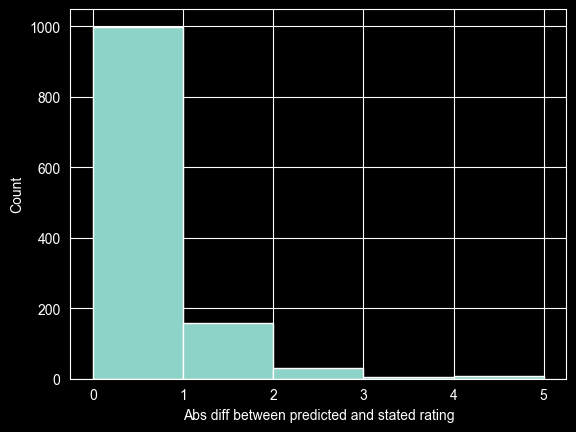

In [5]:
import matplotlib.pyplot as plt

plt.hist(samp["diff"], bins=range(0, 6))
plt.xlabel("Abs diff between predicted and stated rating")
plt.ylabel("Count")
plt.show()